# Chapter 1 · Vectors and spaces

*Book 1 · Linear Algebra · Shelf I -- the first chapter of the shelf*

**Builds on:** nothing but arithmetic. This is where the shelf starts.
**You will:** treat data as vectors, combine them, decide whether a set of vectors is
independent, measure lengths and angles, and see why "how similar are these two?" is a dot
product.

A **vector** is an ordered list of numbers. A row of a table is one; so is an image flattened
into a line, or the counts of words in a document. Linear algebra is the arithmetic of such
lists, and almost every method on this shelf is built from it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from ds_toolbox import viz

viz.use_style()

## Adding and scaling

Two operations define a vector space: add two vectors component by component, and multiply a
vector by a number. Everything else is built from these.

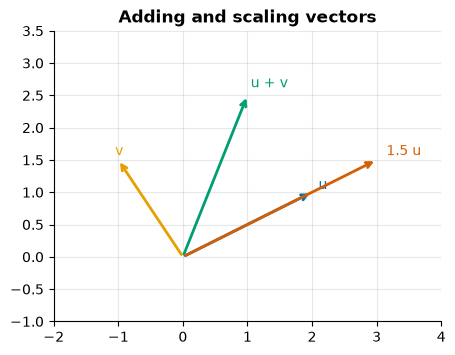

In [2]:
u = np.array([2.0, 1.0])
v = np.array([-1.0, 1.5])
fig, ax = plt.subplots(figsize=(5, 5))
for vec, name, colour in [(u, "u", viz.PALETTE[0]), (v, "v", viz.PALETTE[1]),
                          (u + v, "u + v", viz.PALETTE[2]), (1.5 * u, "1.5 u", viz.PALETTE[3])]:
    ax.annotate("", xy=vec, xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": colour, "lw": 2})
    ax.text(*(vec * 1.05), name, color=colour)
ax.set(xlim=(-2, 4), ylim=(-1, 3.5), aspect="equal", title="Adding and scaling vectors");

## Linear combinations and span

A **linear combination** of vectors is any sum $a\,u + b\,v$. The set of all of them is the
**span**. Two vectors that do not point along the same line span the whole plane: every point
is reachable. Which combination reaches a given point is a system of equations (chapter 3).

In [3]:
target = np.array([1.0, 4.0])
a, b = np.linalg.solve(np.column_stack([u, v]), target)
print(f"{target} = {a:.3f} u + {b:.3f} v  ->  check:", a * u + b * v)

[1. 4.] = 1.375 u + 1.750 v  ->  check: [1. 4.]


## Independence and rank

Vectors are **linearly independent** when none of them is a combination of the others. The
**rank** of a matrix is the number of independent columns -- the dimension of what its columns
span. A table whose columns repeat information has a rank below its width.

In [4]:
rng = np.random.default_rng(1)
height_cm = rng.normal(172, 9, 200)
weight_kg = rng.normal(70, 11, 200)
table = np.column_stack([height_cm, weight_kg, height_cm / 100, height_cm + weight_kg])
print("columns:", table.shape[1], "| rank:", np.linalg.matrix_rank(table))

columns: 4 | rank: 2


Four columns, rank two: the height in metres is the height in centimetres again, and the sum is
a combination of the first two. A model fed this table sees two numbers dressed up as four.

## Length, distance, angle

The **norm** $\lVert x \rVert = \sqrt{x \cdot x}$ is a vector's length; the distance between two
vectors is the norm of their difference. The **dot product** ties length and angle together:

$$x \cdot y = \lVert x \rVert \, \lVert y \rVert \cos\theta$$

In [5]:
def cosine(x, y):
    return x @ y / (np.linalg.norm(x) * np.linalg.norm(y))

print("length of u:", np.linalg.norm(u).round(3), "| distance u-v:", np.linalg.norm(u - v).round(3))
print("angle between u and v:", np.degrees(np.arccos(cosine(u, v))).round(1), "degrees")

length of u: 2.236 | distance u-v: 3.041
angle between u and v: 97.1 degrees


## Similarity is a dot product

Represent three short texts by how often each of five words appears. The cosine of the angle
between two such vectors measures how similar the texts are -- independent of their length.
This is the idea behind search engines and, with learned vectors, behind book 29's embeddings.

In [6]:
words = ["train", "late", "zurich", "cheese", "mountain"]
texts = {
    "commute": np.array([3, 2, 1, 0, 0]),
    "commute, long version": np.array([6, 4, 2, 0, 1]),
    "holiday": np.array([1, 0, 0, 2, 3]),
}
names = list(texts)
sim = np.array([[cosine(texts[a], texts[b]) for b in names] for a in names])
for name, row in zip(names, sim.round(2), strict=True):
    print(f"{name:24s}", row)

commute                  [1.   0.99 0.21]
commute, long version    [0.99 1.   0.32]
holiday                  [0.21 0.32 1.  ]


The long version of the commute text is twice as long but points the same way: cosine close to
1. The holiday text points elsewhere.

## What to remember

- A vector is a list of numbers you can add and scale; data is full of them.
- The rank counts the independent directions -- redundant columns do not add any.
- The dot product measures length and angle at once; cosine similarity ignores length.

## Exercises

1. Add a fifth column `2 * weight_kg - height_cm` to `table`. What is the rank now?
2. Find a vector of length 1 orthogonal to `u`.
3. Why is the Euclidean distance a poor similarity for the word counts above?

**Next:** [Chapter 2 · Matrices as maps](02-matrices-as-maps.ipynb)